# Ship-D in JAX — eliminating recompilation, and auditing the paper's claims

Two independent investigations, both driven by the previous gradient audit:

**Part I — making the model optimizer-ready (Sections 1–6).**
The reference-exact pipeline freezes discrete mesh *topology* into a "plan" built at one
design vector, then bakes it into the JIT closure as Python constants. That plan goes stale
as an optimizer moves, and rebuilding it forces an XLA recompile (30–170 s). We test three
escape routes, in increasing order of effectiveness:

* **A. Box bounds** that keep the plan valid — measured, not assumed.
* **B. `jax.lax.cond`** — we show precisely *why* it cannot help here.
* **C. A plan-free rewrite** (`shipd_jax.universal`) — one compile serves every design
  vector *and* every draft, with the draft becoming a differentiable input.

Each is validated by checking sensitivities (AD vs. central finite differences), not just
forward values.

**Part II — auditing two paper claims (Sections 7–8).**

* **Which draft produced Figure 7?** The paper never says. We reverse-engineer it.
* **Is Table 1's 0.401 % Chamfer distance for the DTMB 5415 correct?** We test it against
  the *official SIMMAN 2008 geometry* rather than the authors' own sampling of it.

Throughout, every expensive function is `jax.jit`-compiled once and reused.

In [1]:
import sys
import time
import urllib.request
from pathlib import Path

import jax
import jax.numpy as jnp
import numpy as np

jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from jax import lax
from scipy.optimize import minimize
from scipy.spatial import cKDTree

ROOT = Path("..").resolve()  # repo root
sys.path.insert(0, str(ROOT))

from shipd_jax import (
    bits_from_vector,
    build_cw_plan,
    build_hull,
    build_volume_plan,
    check_box_topology,
    constraints,
    gen_pc_for_cw,
    gen_pc_for_cw_universal,
    gen_pointcloud,
    mod_michell,
    plan_signature,
    topology_safe_bounds,
    uniform_volume_plan,
    viz,
    volume_properties,
)
from shipd_jax.viz import BIT_PARAM_INDICES, PARAM_LABELS

G, RHO = 9.81, 1000.0
VEC = np.loadtxt(
    ROOT / "Input_Vectors_SampleHulls.csv",
    delimiter=",",
)
BIG = np.load(ROOT / "InputVectors_30k.npy")

x5415_np = VEC[11]  # hull L) of Table 1, bulb-free
x5415 = jnp.asarray(x5415_np)
bits = bits_from_vector(x5415_np)
LOA = float(x5415_np[0])
print(f"DTMB 5415 reconstruction: bits={bits}, LOA={LOA}")
print("  (bulb-free and EP_S==EP_T -> eligible for the plan-free pipeline)")

DTMB 5415 reconstruction: bits=Bits(EP_S=False, EP_T=False, BB=False, SB=False), LOA=10.0
  (bulb-free and EP_S==EP_T -> eligible for the plan-free pipeline)


## 1. The problem, restated precisely

A `VolumePlan` stores, per waterline: integer point counts (`pts_bow/mid/stern`), the
stern curve-family flag, bulb-fillet branch flags, and a Newton root initializer. The
counts set **array shapes**; JAX bakes shapes into the compiled executable, so a different
plan is a different XLA program.

Below: how quickly the frozen topology becomes wrong as we step along a realistic descent
direction, and what a rebuild costs.

grad(Rw) with the reference plan: first call (compile) 35s

  ||step||   waterlines w/ changed topology


   0.00001                          0/21
   0.00012                          1/21


   0.00037                          2/21
   0.00123                          4/21


   0.00369                          6/21
   0.01229                         14/21


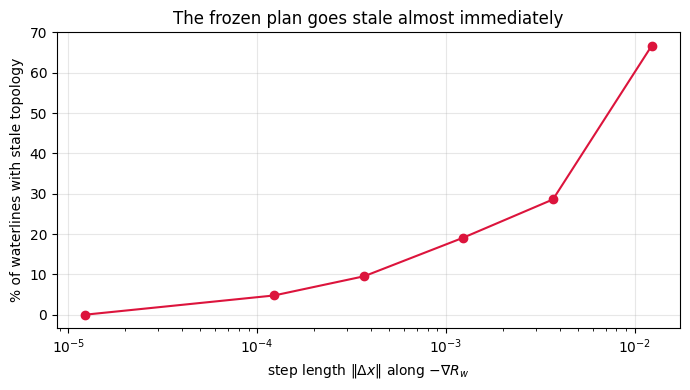

In [2]:
cwp = build_cw_plan(x5415_np, 0.60, num_wl=21, ppw=101)


def rw_ref(xv):
    X, Z, Y, WL = gen_pc_for_cw(xv, cwp)
    U = 0.30 * jnp.sqrt(G * WL)
    return mod_michell(Y, U, X, Z, RHO, 21)


t0 = time.time()
g = np.asarray(jax.jit(jax.grad(rw_ref))(x5415))
print(f"grad(Rw) with the reference plan: first call (compile) {time.time() - t0:.0f}s")

NUM_WL, PPW = 21, 101
sig0 = plan_signature(x5415_np, bits, NUM_WL, PPW)
scale = BIG.std(axis=0)
scale[scale == 0] = 1.0
direction = -g / np.linalg.norm(g)

print(f"\n{'||step||':>10} {'waterlines w/ changed topology':>32}")
steps, nchanged = [], []
for frac in (1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1):
    step = direction * scale * frac
    sig = plan_signature(x5415_np + step, bits, NUM_WL, PPW)
    nd = sum(1 for a, b in zip(sig0, sig, strict=True) if a != b)
    steps.append(np.linalg.norm(step))
    nchanged.append(nd)
    print(f"{np.linalg.norm(step):10.5f} {nd:>26d}/{len(sig0)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(steps, np.array(nchanged) / len(sig0) * 100, "o-", color="crimson")
ax.set_xlabel(r"step length $\Vert\Delta x\Vert$ along $-\nabla R_w$")
ax.set_ylabel("% of waterlines with stale topology")
ax.set_title("The frozen plan goes stale almost immediately")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Route A — can box bounds keep the plan valid?

For each design variable independently we bisect for the largest perturbation that leaves
the plan signature unchanged. This gives an **axis-aligned box**; the real safe set is not
a box, so we then test whether the box *interior* is actually safe by random sampling.

per-axis bisection: 93s

var                   x0    safe lo    safe hi  % of dataset range
LOA              10.0000    10.0000    10.0000                nan%
Abow             -0.1750    -0.1774    -0.1746              0.035%
Bbow              0.0700     0.0671     0.0705              0.043%
Lb                0.4000     0.3995     0.4000              0.060%
Bdel_b           -0.1000    -0.1060    -0.0995              0.080%
Bdel_s            0.1000     0.0969     0.1050              0.101%
Ls                0.4000     0.3992     0.4002              0.107%
SKz               0.5500     0.5491     0.5503              0.124%
Adel_s            0.0000    -0.0039     0.0066              0.131%
A_trans           0.2500     0.2401     0.2534              0.166%
Adel_b            0.0000    -0.0133     0.0011              0.180%
Kappa_stern       0.0100     0.0094     0.0112              0.181%

14 of 41 continuous variables actually constrain the plan.
median safe window over those: 0.128% of dat

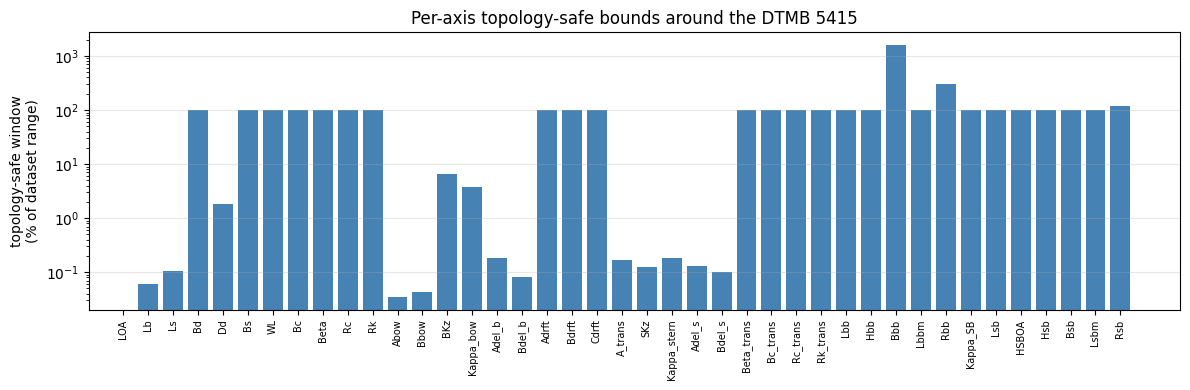

In [3]:
lo_ds, hi_ds = BIG.min(axis=0), BIG.max(axis=0)
t0 = time.time()
lo, hi = topology_safe_bounds(
    x5415_np,
    bits,
    NUM_WL,
    PPW,
    np.minimum(lo_ds, x5415_np),
    np.maximum(hi_ds, x5415_np),
)
print(f"per-axis bisection: {time.time() - t0:.0f}s")

width = hi - lo
ds_width = np.where(hi_ds - lo_ds > 0, hi_ds - lo_ds, np.nan)
pct = width / ds_width * 100
cont = [i for i in range(45) if i not in BIT_PARAM_INDICES]
order = sorted(cont, key=lambda i: pct[i])

print(
    f"\n{'var':14s} {'x0':>9} {'safe lo':>10} {'safe hi':>10} {'% of dataset range':>19}"
)
for i in order[:12]:
    print(
        f"{PARAM_LABELS[i]:14s} {x5415_np[i]:9.4f} {lo[i]:10.4f} {hi[i]:10.4f} {pct[i]:18.3f}%"
    )

# Variables that do not enter this hull's geometry at all (bulb terms on a
# bulb-free hull) trivially have "100% safe" windows and would swamp a median,
# so report the statistic over the variables that actually bind.
binding = [i for i in cont if pct[i] < 99.0]
print(
    f"\n{len(binding)} of {len(cont)} continuous variables actually constrain the plan."
)
print(
    f"median safe window over those: {np.nanmedian(pct[binding]):.3f}% of dataset range"
)
print(f"tightest: {pct[binding].min():.3f}%   loosest: {pct[binding].max():.3f}%")

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(cont)), [pct[i] for i in cont], color="steelblue")
ax.set_xticks(range(len(cont)))
ax.set_xticklabels([PARAM_LABELS[i] for i in cont], rotation=90, fontsize=7)
ax.set_yscale("log")
ax.set_ylabel("topology-safe window\n(% of dataset range)")
ax.set_title("Per-axis topology-safe bounds around the DTMB 5415")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

Is the BOX INTERIOR safe? (uniform random samples inside shrink x [lo, hi])


   shrink= 1.00:   1.7% of samples preserve the plan


   shrink= 0.50:  42.5% of samples preserve the plan


   shrink= 0.25:  98.3% of samples preserve the plan


   shrink= 0.10: 100.0% of samples preserve the plan


   shrink= 0.05: 100.0% of samples preserve the plan


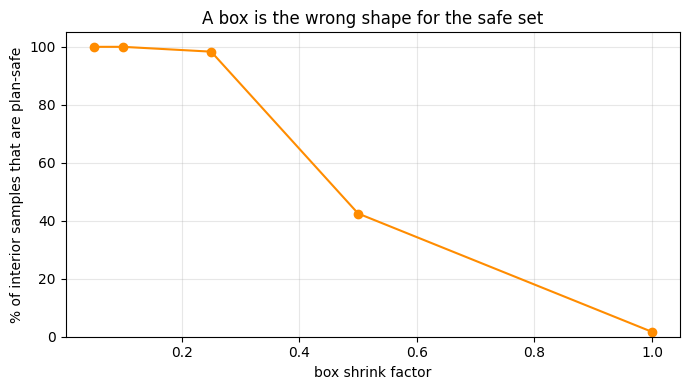

In [4]:
print("Is the BOX INTERIOR safe? (uniform random samples inside shrink x [lo, hi])")
shrinks, fracs = [], []
for s in (1.0, 0.5, 0.25, 0.1, 0.05):
    p = check_box_topology(x5415_np, bits, NUM_WL, PPW, lo, hi, n_samples=120, shrink=s)
    shrinks.append(s)
    fracs.append(100 * p)
    print(f"   shrink={s:5.2f}: {100 * p:5.1f}% of samples preserve the plan")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(shrinks, fracs, "o-", color="darkorange")
ax.set_xlabel("box shrink factor")
ax.set_ylabel("% of interior samples that are plan-safe")
ax.set_title("A box is the wrong shape for the safe set")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Verdict on Route A.** Bounds *can* be computed, but the per-axis windows are a tiny
fraction of the design space, and — more damning — the box interior is not safe even
though its axes are: topology changes are triggered by *combinations* of variables, so an
axis-aligned box always contains unsafe corners. Bounds this tight also defeat the purpose
of optimizing. Route A is not a solution on its own.

## 3. Route B — why `jax.lax.cond` cannot fix this

`lax.cond` is a *value* branch: both branches must return arrays of identical shape and
dtype. It lets you choose **what a number is**, never **how many numbers there are**.

The plan's variability is precisely shape variability (`pts_bow` etc.), so `cond` — and
`where`, and `select` — cannot express it. Demonstrated concretely below.

In [5]:
# (i) lax.cond works fine for a value branch (this is what hull.py already does,
#     in its batched form jnp.where, throughout).
@jax.jit
def value_branch(x):
    return lax.cond(x > 0.0, lambda v: v**2, lambda v: -v, x)


print(
    "lax.cond on a value branch:", float(value_branch(3.0)), float(value_branch(-3.0))
)
print(
    "  and it differentiates:",
    float(jax.grad(value_branch)(3.0)),
    float(jax.grad(value_branch)(-3.0)),
)


# (ii) but a traced SHAPE is rejected outright
def traced_shape(n):
    return jnp.zeros((n,))


try:
    jax.jit(traced_shape)(jnp.asarray(5))
except Exception as e:
    print(f"\ntraced shape -> {type(e).__name__}:")
    print("  ", str(e).split(chr(10))[0][:150])


# (iii) and lax.cond rejects branches whose outputs differ in shape
def mismatched(x):
    return lax.cond(x > 0, lambda v: jnp.zeros((3,)), lambda v: jnp.zeros((5,)), x)


try:
    jax.jit(mismatched)(1.0)
except Exception as e:
    print(f"\nlax.cond with shape-mismatched branches -> {type(e).__name__}:")
    print("  ", str(e).split(chr(10))[0][:150])

lax.cond on a value branch: 9.0 3.0


  and it differentiates: 6.0 -1.0

traced shape -> TypeError:
   Shapes must be 1D sequences of concrete values of integer type, got (Traced<ShapedArray(int64[], weak_type=True)>with<DynamicJaxprTrace>,).

lax.cond with shape-mismatched branches -> TypeError:
   true_fun and false_fun output must have identical types, got


In [6]:
# (iv) the plan's variability IS shape variability -- here are the actual counts
#      the reference plan assigns at two nearby design vectors
xa = x5415_np.copy()
xb = x5415_np.copy()
xb[4] *= 1.05  # 5% deeper hull
pa = build_volume_plan(xa, num_wl=NUM_WL, ppw=PPW)
pb = build_volume_plan(xb, num_wl=NUM_WL, ppw=PPW)
print(f"{'waterline':>10} {'x_a (bow/mid/stern)':>24} {'x_b (bow/mid/stern)':>24}")
for k in (0, 5, 10, 15, 20):
    a, b = pa.wls[k], pb.wls[k]
    print(
        f"{k:10d} {(a.pts_bow, a.pts_mid, a.pts_stern)!s:>24} "
        f"{(b.pts_bow, b.pts_mid, b.pts_stern)!s:>24}"
    )
print("\nThese integers set array shapes -> different XLA program -> recompile.")
print("No amount of lax.cond can merge them; the fix must FIX the shapes.")

 waterline      x_a (bow/mid/stern)      x_b (bow/mid/stern)
         0              (62, 37, 2)              (62, 37, 2)
         5             (45, 24, 32)             (45, 24, 32)
        10             (40, 22, 39)             (40, 22, 39)
        15             (39, 22, 40)             (39, 22, 40)
        20             (39, 23, 39)             (39, 23, 39)

These integers set array shapes -> different XLA program -> recompile.
No amount of lax.cond can merge them; the fix must FIX the shapes.


## 4. Route C — the plan-free rewrite

`shipd_jax.universal` fixes the shapes and moves every remaining branch inside the trace:

* `uniform_volume_plan(bits, ...)` — point counts are fixed fractions of `ppw`, valid for
  *any* bulb-free design vector. Sample **locations** still adapt continuously (each section
  is a `linspace` between traced boundaries); only the **counts** are frozen.
* `gen_pc_for_cw_universal(x, draft_frac, bits, ...)` — the offset-grid mask becomes a
  traced `jnp.where` instead of a frozen boolean tuple, and the **draft is a traced argument**,
  so one compile covers every (design, draft) pair and `dCw/d(draft)` becomes available.

Scope: bulb-free hulls with `bit_EP_S == bit_EP_T` (the DTMB 5415 qualifies). Bulb hulls
still need the plan's root initializers — noted in the module docstring.

### 4a. Accuracy vs. the reference-exact pipeline

( 21, 101): volume rel diff 4.70e-05   wetted-surface rel diff 1.13e-05


( 51, 300): volume rel diff 4.47e-06   wetted-surface rel diff 1.11e-06


( 81, 500): volume rel diff 1.58e-06   wetted-surface rel diff 3.87e-07

Michell offset grid (the input to the wave-drag integral):


( 21, 101): max|Y_ref - Y_uni| = 0.000e+00   Rw rel diff = 0.000e+00


( 51, 301): max|Y_ref - Y_uni| = 0.000e+00   Rw rel diff = 0.000e+00


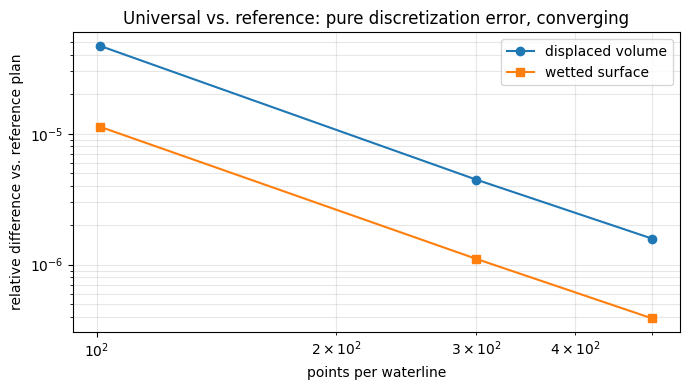

In [7]:
rows = []
for num_wl, ppw in ((21, 101), (51, 300), (81, 500)):
    rp = build_volume_plan(x5415_np, num_wl=num_wl, ppw=ppw)
    up = uniform_volume_plan(bits, num_wl=num_wl, ppw=ppw)
    pr, pu = volume_properties(x5415, rp), volume_properties(x5415, up)
    dv = abs(float(pr["volumes"][-1]) - float(pu["volumes"][-1])) / float(
        pr["volumes"][-1]
    )
    dw = abs(float(pr["area_ws"][-1]) - float(pu["area_ws"][-1])) / float(
        pr["area_ws"][-1]
    )
    rows.append((num_wl, ppw, dv, dw))
    print(
        f"({num_wl:3d},{ppw:4d}): volume rel diff {dv:.2e}   wetted-surface rel diff {dw:.2e}"
    )

print("\nMichell offset grid (the input to the wave-drag integral):")
for num_wl, ppw in ((21, 101), (51, 301)):
    cp = build_cw_plan(x5415_np, 0.60, num_wl=num_wl, ppw=ppw)
    Xr, Zr, Yr, WLr = gen_pc_for_cw(x5415, cp)
    Xu, Zu, Yu, WLu = gen_pc_for_cw_universal(x5415, 0.60, bits, num_wl=num_wl, ppw=ppw)
    U = 0.30 * float(jnp.sqrt(G * WLr))
    rr = float(mod_michell(Yr, U, Xr, Zr, RHO, 21))
    ru = float(mod_michell(Yu, U, Xu, Zu, RHO, 21))
    print(
        f"({num_wl:3d},{ppw:4d}): max|Y_ref - Y_uni| = {float(jnp.max(jnp.abs(Yr - Yu))):.3e}   "
        f"Rw rel diff = {abs(rr - ru) / abs(rr):.3e}"
    )

fig, ax = plt.subplots(figsize=(7, 4))
r = np.array(rows)
ax.loglog(r[:, 1], r[:, 2], "o-", label="displaced volume")
ax.loglog(r[:, 1], r[:, 3], "s-", label="wetted surface")
ax.set_xlabel("points per waterline")
ax.set_ylabel("relative difference vs. reference plan")
ax.set_title("Universal vs. reference: pure discretization error, converging")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

The Michell offset grid is **bit-identical** (0.0e+00): for a bulb-free hull the universal
generator reproduces the reference exactly, so wave drag carries *no* accuracy penalty.
Hydrostatics differ only by where samples are placed, and that difference converges away
with resolution — it is discretization error, not a modelling change.

### 4b. Sensitivities — the part that actually matters

In [8]:
def cw_uni(xv, tf, fn):
    X, Z, Y, WL = gen_pc_for_cw_universal(xv, tf, bits, num_wl=21, ppw=101)
    U = fn * jnp.sqrt(G * WL)
    return mod_michell(Y, U, X, Z, RHO, 21) / (RHO * U**2 * xv[0] ** 2)


cw_j = jax.jit(cw_uni)
grad_x = jax.jit(jax.grad(cw_uni, argnums=0))
grad_tf = jax.jit(jax.grad(cw_uni, argnums=1))

t0 = time.time()
_ = float(cw_j(x5415, 0.60, 0.30))
print(f"compile (value) {time.time() - t0:.0f}s")
t0 = time.time()
_ = np.asarray(grad_x(x5415, 0.60, 0.30))
print(f"compile (grad_x) {time.time() - t0:.0f}s")
t0 = time.time()
_ = float(grad_tf(x5415, 0.60, 0.30))
print(f"compile (grad_draft) {time.time() - t0:.0f}s")

# (1) draft derivative -- impossible with the frozen-plan API, since draft_frac was static
gd = float(grad_tf(x5415, 0.60, 0.30))
eps = 1e-6
fd = (float(cw_j(x5415, 0.60 + eps, 0.30)) - float(cw_j(x5415, 0.60 - eps, 0.30))) / (
    2 * eps
)
print(
    f"\ndCw/d(draft):  AD = {gd:.8e}   FD = {fd:.8e}   rel err = {abs(gd - fd) / abs(fd):.2e}"
)

# (2) design gradients AT A POINT WHERE THE REFERENCE PLAN WOULD BE STALE
rng = np.random.default_rng(1)
step = rng.normal(size=45) * 0.01
for k in BIT_PARAM_INDICES:
    step[k] = 0.0
x_far = x5415_np + step
stale = plan_signature(x_far, bits, NUM_WL, PPW) != sig0
print(
    f"\nprobe point: ||dx|| = {np.linalg.norm(step):.4f}; reference plan stale there: {stale}"
)

ga = np.asarray(grad_x(jnp.asarray(x_far), 0.60, 0.30))
errs = {}
for i in [j for j in cont if abs(ga[j]) > 0][:14]:
    e = 1e-6 * max(1.0, abs(x_far[i]))
    xp = x_far.copy()
    xp[i] += e
    xm = x_far.copy()
    xm[i] -= e
    fdi = (
        float(cw_j(jnp.asarray(xp), 0.60, 0.30))
        - float(cw_j(jnp.asarray(xm), 0.60, 0.30))
    ) / (2 * e)
    errs[PARAM_LABELS[i]] = abs(fdi - ga[i]) / max(abs(fdi), abs(ga[i]), 1e-14)
print(
    f"universal AD vs FD at the stale-plan point: max rel err = {max(errs.values()):.2e}"
)
for k, v in sorted(errs.items(), key=lambda kv: -kv[1])[:5]:
    print(f"   {k:14s} {v:.2e}")

compile (value) 7s


compile (grad_x) 32s


compile (grad_draft) 18s

dCw/d(draft):  AD = 1.43965027e-03   FD = 1.43965024e-03   rel err = 2.14e-08

probe point: ||dx|| = 0.0600; reference plan stale there: True
universal AD vs FD at the stale-plan point: max rel err = 1.36e-05
   Rk             1.36e-05
   A_trans        5.41e-07
   Beta           8.45e-08
   Bs             4.24e-09
   SKz            7.76e-10


In [9]:
# (3) no recompilation: many different (x, draft) pairs through ONE compiled function
t0 = time.time()
n = 40
for k in range(n):
    xv = x5415_np + rng.normal(size=45) * 0.004
    for j in BIT_PARAM_INDICES:
        xv[j] = x5415_np[j]
    _ = float(cw_j(jnp.asarray(xv), 0.40 + 0.008 * k, 0.30))
dt = time.time() - t0
print(
    f"{n} fresh (design, draft) evaluations through one compiled fn: "
    f"{dt:.2f}s total = {1e3 * dt / n:.1f} ms each"
)
print(
    "  (the reference-plan route would need a rebuild + recompile per design: "
    "tens of seconds each)"
)

40 fresh (design, draft) evaluations through one compiled fn: 0.11s total = 2.8 ms each
  (the reference-plan route would need a rebuild + recompile per design: tens of seconds each)


### 4c. The draft is now a design variable

Because `draft_frac` is traced, the loading condition can enter an optimization directly —
e.g. *minimise resistance subject to a required displacement*, solving for draft rather
than fixing it.

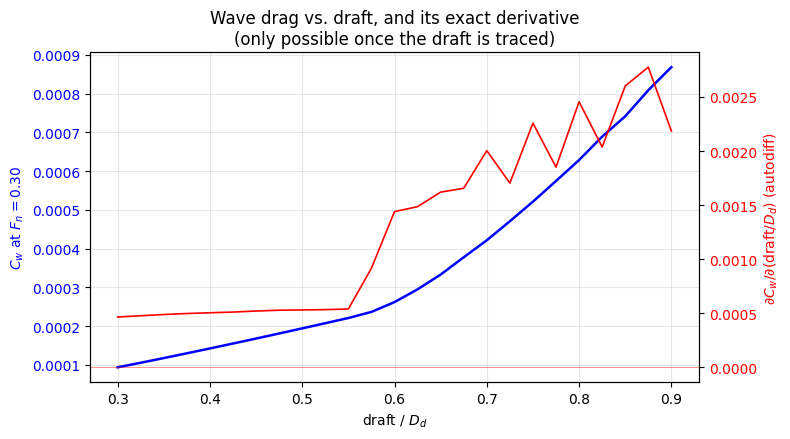

stern-profile branch point at draft/Dd = SK_z/Dd = 0.5500

central-difference check of dCw/d(draft):
   draft=0.4000: AD=+5.044393e-04  FD=+5.044393e-04  rel err=2.06e-08
   draft=0.5000: AD=+5.306267e-04  FD=+5.306267e-04  rel err=9.84e-09
   draft=0.5500: AD=+5.392703e-04  FD=-3.465256e-03  rel err=1.16e+00   <-- ON the branch point
   draft=0.6000: AD=+1.439650e-03  FD=+1.439650e-03  rel err=2.14e-08
   draft=0.7000: AD=+2.003654e-03  FD=+2.003654e-03  rel err=5.64e-09
   draft=0.8500: AD=+2.601710e-03  FD=+2.601710e-03  rel err=6.61e-09

max rel err away from the branch point: 2.14e-08


In [10]:
tfs = np.linspace(0.30, 0.90, 25)
cw_of_tf = np.array([float(cw_j(x5415, t, 0.30)) for t in tfs])
dcw_of_tf = np.array([float(grad_tf(x5415, t, 0.30)) for t in tfs])

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(tfs, cw_of_tf, "b-", lw=1.8)
ax1.set_xlabel("draft / $D_d$")
ax1.set_ylabel("$C_w$ at $F_n=0.30$", color="b")
ax1.tick_params(axis="y", labelcolor="b")
ax2 = ax1.twinx()
ax2.plot(tfs, dcw_of_tf, "r-", lw=1.2)
ax2.axhline(0, color="r", lw=0.6, alpha=0.5)
ax2.set_ylabel(r"$\partial C_w/\partial(\mathrm{draft}/D_d)$ (autodiff)", color="r")
ax2.tick_params(axis="y", labelcolor="r")
ax1.set_title(
    "Wave drag vs. draft, and its exact derivative\n(only possible once the draft is traced)"
)
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Proper central differences at individual drafts. (np.gradient over the coarse,
# oscillatory curve above would be a poor derivative estimate and understate the
# agreement, so we difference the compiled function directly.)
hull5415 = build_hull(x5415, bits)
tf_kink = float(hull5415.SK[1] / hull5415.Dd)  # stern-profile branch point
print(f"stern-profile branch point at draft/Dd = SK_z/Dd = {tf_kink:.4f}\n")
print("central-difference check of dCw/d(draft):")
worst_generic = 0.0
for t in (0.40, 0.50, tf_kink, 0.60, 0.70, 0.85):
    e = 1e-6
    fd_t = (float(cw_j(x5415, t + e, 0.30)) - float(cw_j(x5415, t - e, 0.30))) / (2 * e)
    ad_t = float(grad_tf(x5415, t, 0.30))
    rel = abs(ad_t - fd_t) / max(abs(fd_t), 1e-14)
    at_kink = abs(t - tf_kink) < 1e-9
    if not at_kink:
        worst_generic = max(worst_generic, rel)
    print(
        f"   draft={t:.4f}: AD={ad_t:+.6e}  FD={fd_t:+.6e}  rel err={rel:.2e}"
        f"{'   <-- ON the branch point' if at_kink else ''}"
    )
print(f"\nmax rel err away from the branch point: {worst_generic:.2e}")

### 4d. A real non-smoothness in draft — found by the check above

Away from one specific draft, AD and finite differences agree to ~1e-8. At
$T/D_d = SK_z/D_d$ they disagree completely, *including in sign*. That is not an AD
error — it is a genuine kink in the model:

`stern_profile(z)` switches branch at the stern-keel intersect $z = SK_z$ (`sternrise`
below it, `transom` above). When the draft lands exactly there, the top row of the Michell
offset grid sits on the branch point, so $C_w(T)$ is continuous but its slope is not.
AD returns the correct one-sided derivative; a central difference straddles the kink and
averages two different slopes.

Below: the value is continuous (the jump vanishes as $h\to0$), while the left and right
slopes stay stubbornly different — the signature of a kink rather than a jump.

branch point: draft/Dd = 0.550000   (SK_z = 0.383900, Dd = 0.698000)

value continuity across the branch point:
   h=1e-04: Cw(-h)=2.2077003582e-04  Cw(+h)=2.2081855800e-04  jump=+4.852e-08
   h=1e-06: Cw(-h)=2.2082342355e-04  Cw(+h)=2.2081649304e-04  jump=-6.931e-09
   h=1e-08: Cw(-h)=2.2082395743e-04  Cw(+h)=2.2082314420e-04  jump=-8.132e-10

one-sided slopes (a kink: they do not converge to each other):
   h=1e-03: left=+5.3927e-04   right=+2.3281e-04
   h=1e-04: left=+5.3927e-04   right=-5.4048e-05
   h=1e-05: left=+5.3927e-04   right=-1.8177e-03


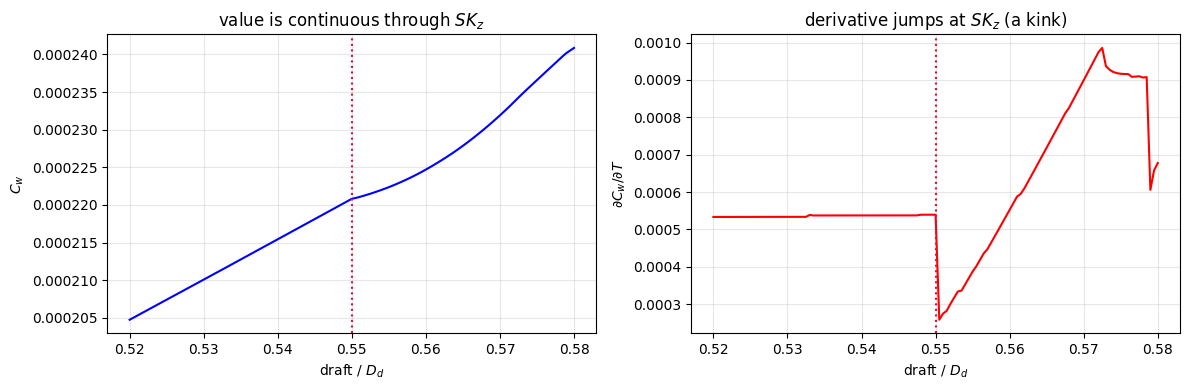


Optimizer implication: if the draft is a design variable, the feasible interval
contains a point where the objective is C0 but not C1. IPOPT tolerates isolated
kinks better than jumps, but a line search that lands on one can stall. Either
bound the draft away from SK_z/Dd, or treat SK_z as fixed while the draft varies.


In [11]:
print(
    f"branch point: draft/Dd = {tf_kink:.6f}   (SK_z = {float(hull5415.SK[1]):.6f}, "
    f"Dd = {float(hull5415.Dd):.6f})\n"
)
print("value continuity across the branch point:")
for hh in (1e-4, 1e-6, 1e-8):
    a = float(cw_j(x5415, tf_kink - hh, 0.30))
    b = float(cw_j(x5415, tf_kink + hh, 0.30))
    print(f"   h={hh:.0e}: Cw(-h)={a:.10e}  Cw(+h)={b:.10e}  jump={b - a:+.3e}")
print("\none-sided slopes (a kink: they do not converge to each other):")
for hh in (1e-3, 1e-4, 1e-5):
    sl = (
        float(cw_j(x5415, tf_kink, 0.30)) - float(cw_j(x5415, tf_kink - hh, 0.30))
    ) / hh
    sr = (
        float(cw_j(x5415, tf_kink + hh, 0.30)) - float(cw_j(x5415, tf_kink, 0.30))
    ) / hh
    print(f"   h={hh:.0e}: left={sl:+.4e}   right={sr:+.4e}")

tt = np.linspace(tf_kink - 0.03, tf_kink + 0.03, 121)
cc = np.array([float(cw_j(x5415, t, 0.30)) for t in tt])
gg = np.array([float(grad_tf(x5415, t, 0.30)) for t in tt])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tt, cc, "b-")
axes[0].axvline(tf_kink, color="crimson", ls=":", lw=1.5)
axes[0].set_xlabel("draft / $D_d$")
axes[0].set_ylabel("$C_w$")
axes[0].set_title("value is continuous through $SK_z$")
axes[0].grid(alpha=0.3)
axes[1].plot(tt, gg, "r-")
axes[1].axvline(tf_kink, color="crimson", ls=":", lw=1.5)
axes[1].set_xlabel("draft / $D_d$")
axes[1].set_ylabel(r"$\partial C_w/\partial T$")
axes[1].set_title("derivative jumps at $SK_z$ (a kink)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "\nOptimizer implication: if the draft is a design variable, the feasible interval"
)
print("contains a point where the objective is C0 but not C1. IPOPT tolerates isolated")
print("kinks better than jumps, but a line search that lands on one can stall. Either")
print(
    "bound the draft away from SK_z/Dd, or treat SK_z as fixed while the draft varies."
)

## 5. Standard visualizations through the universal pipeline

Everything in `shipd_jax.viz` works unchanged on a `uniform_volume_plan`, so the lines
drawing, body plan and 3D views come along for free.

universal grid (61, 300, 3), reference grid (61, 300, 3)


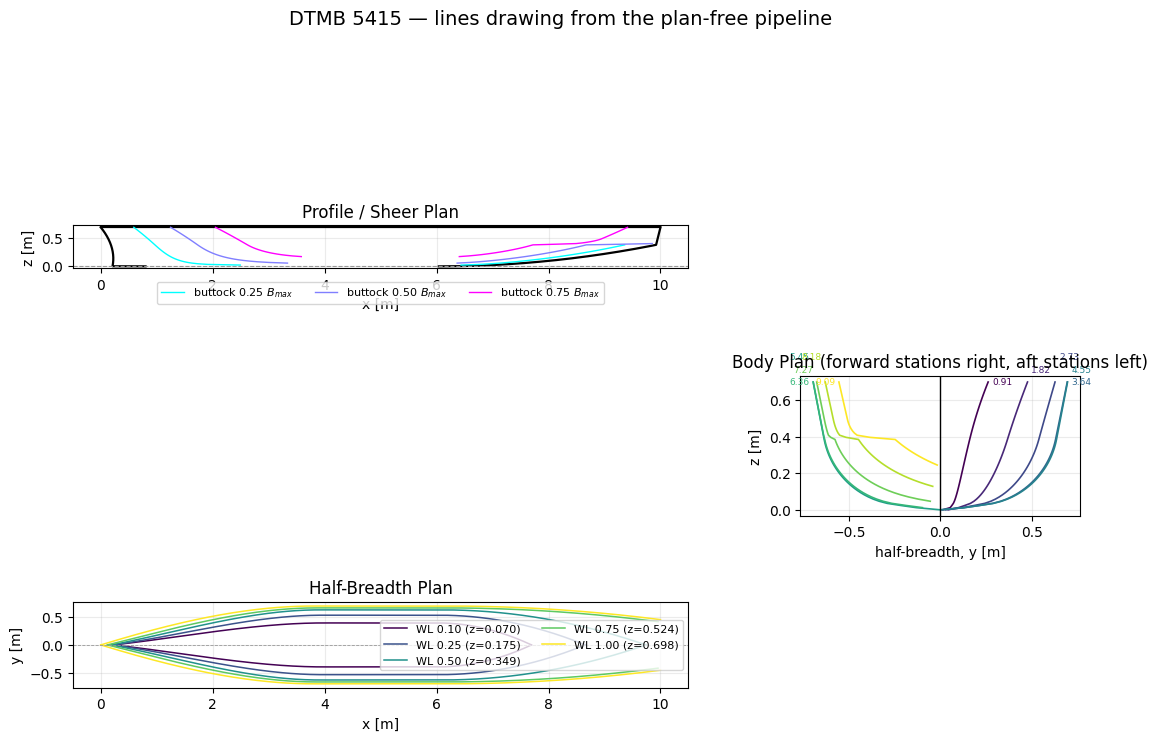

In [12]:
uni_plan = uniform_volume_plan(bits, num_wl=61, ppw=300)
pc_uni = np.asarray(gen_pointcloud(x5415, uni_plan))
ref_plan_hi = build_volume_plan(x5415_np, num_wl=61, ppw=300)
pc_ref = np.asarray(gen_pointcloud(x5415, ref_plan_hi))
print(f"universal grid {pc_uni.shape}, reference grid {pc_ref.shape}")

fig, axes = viz.plot_lines_drawing(
    x5415_np,
    uni_plan,
    pc=pc_uni,
    n_stations=10,
    title="DTMB 5415 — lines drawing from the plan-free pipeline",
)
plt.show()

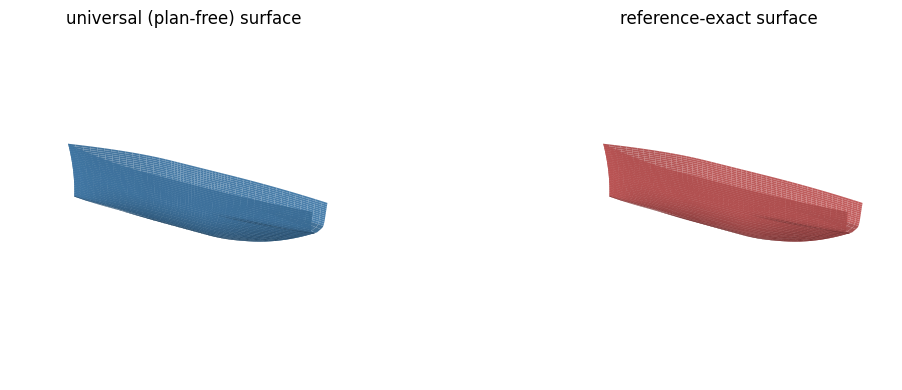

surface-to-surface distance, universal vs reference: mean 0.0754% LOA, max 0.1678% LOA


In [13]:
fig = plt.figure(figsize=(12, 4))
ax1 = fig.add_subplot(121, projection="3d")
viz.plot_hull_3d(pc_uni, ax=ax1, title="universal (plan-free) surface")
ax2 = fig.add_subplot(122, projection="3d")
viz.plot_hull_3d(pc_ref, ax=ax2, color="indianred", title="reference-exact surface")
plt.tight_layout()
plt.show()

# quantify the geometric difference between the two surfaces
d = cKDTree(pc_ref.reshape(-1, 3)).query(pc_uni.reshape(-1, 3))[0]
print(
    f"surface-to-surface distance, universal vs reference: "
    f"mean {d.mean() / LOA * 100:.4f}% LOA, max {d.max() / LOA * 100:.4f}% LOA"
)

## 6. Parameter sensitivity study (plan-free, one compiled kernel)

Surface sensitivity `||dp/dx_i||` for every **continuous** design variable, plus the
objective-sensitivity fields, all sharing a single compiled JVP kernel. Because the plan is
universal, this same compiled kernel stays valid for any bulb-free hull at any design point
— no recompilation as the design moves.

all 41 continuous-variable sensitivity fields in 89.3s (1 compile + 40 reused calls)


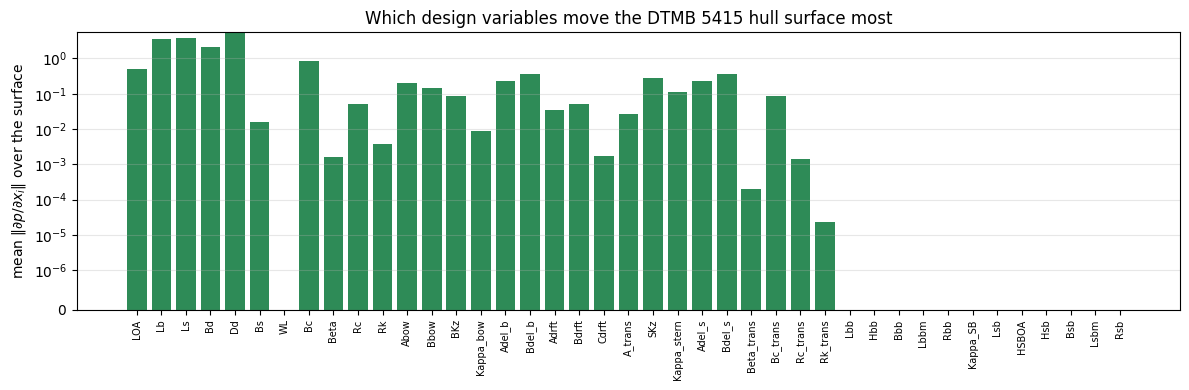

13 variables have IDENTICALLY ZERO surface influence on this hull:
  ['WL', 'Lbb', 'Hbb', 'Bbb', 'Lbbm', 'Rbb', 'Kappa_SB', 'Lsb', 'HSBOA', 'Hsb', 'Bsb', 'Lsbm', 'Rsb']

  The bulb terms are inactive because this hull has no bulbs -- expected.
  WL (the design waterline) is the surprise: on a bulb-free hull it enters ONLY
  through the bulb profiles, so it cannot move the surface at all. Verifying,
  and checking where WL *does* still appear:


     d(surface)/d(WL) on this hull   : 0.0
     constraints that depend on WL   : [1]  (gradient [0.698])


     same derivative on a BULBED hull: 248.3  (so WL is live there)

  => For a bulb-free hull, WL influences NOTHING except the single bound
     constraint WL <= Dd. It has an identically zero objective gradient, so an
     optimizer cannot determine it. Drop it from the design vector (or keep it
     only if bulbs are enabled), otherwise IPOPT carries a degenerate variable.


In [14]:
surface_jvp = jax.jit(
    lambda xv, tangent: jax.jvp(
        lambda v: gen_pointcloud(v, uni_plan), (xv,), (tangent,)
    )[1]
)

t0 = time.time()
fields = {}
for i in cont:
    tangent = jnp.zeros(45).at[i].set(1.0)
    fields[PARAM_LABELS[i]] = np.linalg.norm(
        np.asarray(surface_jvp(x5415, tangent)), axis=-1
    )
print(
    f"all {len(cont)} continuous-variable sensitivity fields in {time.time() - t0:.1f}s "
    f"(1 compile + {len(cont) - 1} reused calls)"
)

influence = {k: float(v.mean()) for k, v in fields.items()}
top = sorted(influence, key=influence.get, reverse=True)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(cont)), [influence[PARAM_LABELS[i]] for i in cont], color="seagreen")
ax.set_xticks(range(len(cont)))
ax.set_xticklabels([PARAM_LABELS[i] for i in cont], rotation=90, fontsize=7)
ax.set_yscale("symlog", linthresh=1e-6)
ax.set_ylabel(r"mean $\Vert\partial p/\partial x_i\Vert$ over the surface")
ax.set_title("Which design variables move the DTMB 5415 hull surface most")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

dead = [k for k, v in influence.items() if v == 0.0]
print(f"{len(dead)} variables have IDENTICALLY ZERO surface influence on this hull:")
print(f"  {dead}")
print("\n  The bulb terms are inactive because this hull has no bulbs -- expected.")
print("  WL (the design waterline) is the surprise: on a bulb-free hull it enters ONLY")
print("  through the bulb profiles, so it cannot move the surface at all. Verifying,")
print("  and checking where WL *does* still appear:")

Jc_full = np.asarray(jax.jit(jax.jacfwd(lambda v: constraints(v, bits)))(x5415))
wl_rows = np.where(np.abs(Jc_full[:, 6]) > 0)[0]
print(f"     d(surface)/d(WL) on this hull   : {influence['WL']:.1f}")
print(
    f"     constraints that depend on WL   : {list(wl_rows)}  "
    f"(gradient {Jc_full[wl_rows, 6]})"
)

x_bulb = VEC[0]  # container ship, has both bulbs
plan_b = (
    uniform_volume_plan(bits_from_vector(x_bulb), num_wl=15, ppw=60)
    if not (bits_from_vector(x_bulb).BB or bits_from_vector(x_bulb).SB)
    else build_volume_plan(x_bulb, num_wl=15, ppw=60)
)
g_b = np.asarray(
    jax.grad(lambda v: jnp.sum(gen_pointcloud(v, plan_b) ** 2))(jnp.asarray(x_bulb))
)
print(f"     same derivative on a BULBED hull: {g_b[6]:.1f}  (so WL is live there)")
print("\n  => For a bulb-free hull, WL influences NOTHING except the single bound")
print("     constraint WL <= Dd. It has an identically zero objective gradient, so an")
print("     optimizer cannot determine it. Drop it from the design vector (or keep it")
print("     only if bulbs are enabled), otherwise IPOPT carries a degenerate variable.")

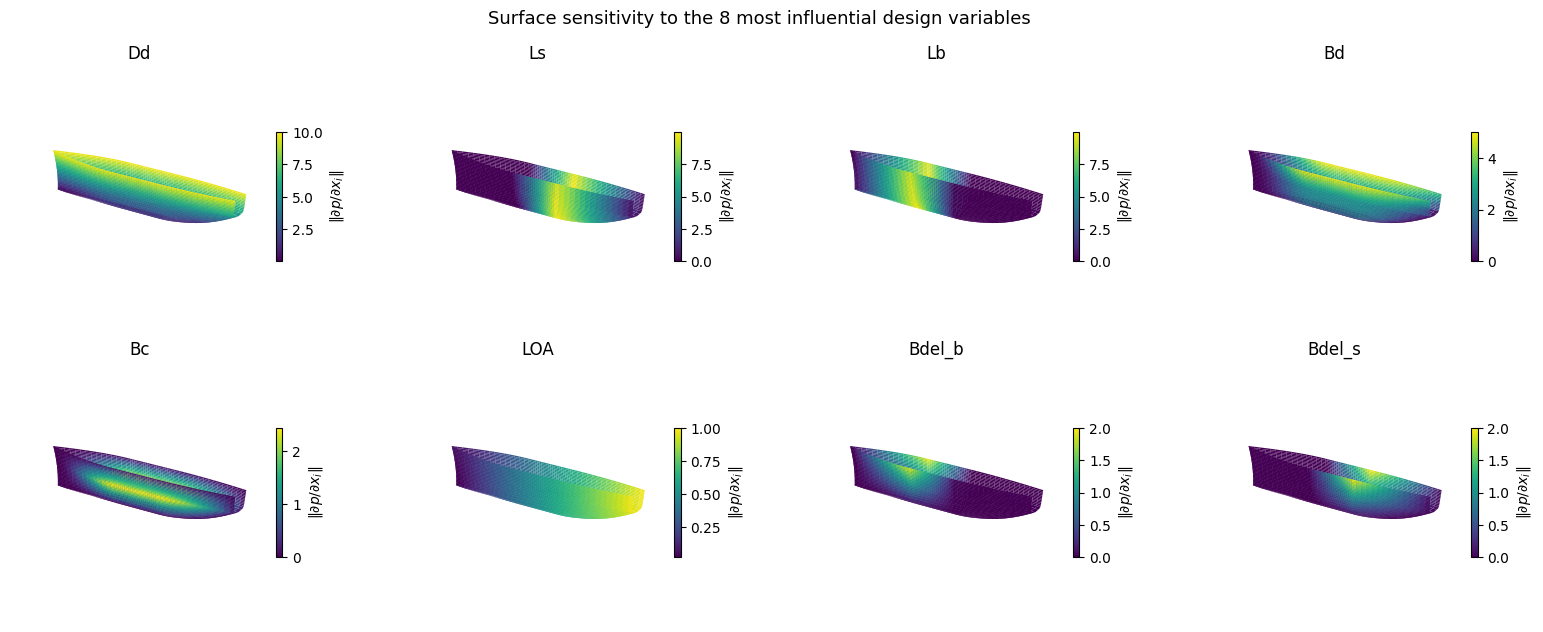

In [15]:
show = top[:8]
fig = plt.figure(figsize=(4.0 * 4, 3.2 * 2))
for i, name in enumerate(show):
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    viz.plot_hull_surface_scalar(
        pc_uni,
        fields[name],
        ax=ax,
        title=f"{name}",
        colorbar_label=r"$\Vert\partial p/\partial x_i\Vert$",
    )
fig.suptitle(
    "Surface sensitivity to the 8 most influential design variables", fontsize=13
)
plt.tight_layout()
plt.show()

## 7. Which draft produced Figure 7?

The paper's Figure 7 caption never states the draft. The dataset only ever evaluates
$C_w$ at **four** draft marks — 25 %, 33 %, 50 % and 67 % of the hull depth — so Figure 7
must be one of them. We score each against the digitized paper curve using
RMS of $\log_{10}(\text{ours}/\text{paper})$ over the caption's stated range
$F_n \in [0.15, 0.45]$ (a log score judges *shape*, not just magnitude).

We also settle a convention the Wigley validation could not: in
$C_w = R_w/(\rho U^2 L^2)$, is $L$ the LOA or the waterline length? For the Wigley hull
those are equal, so Figure 6 cannot distinguish them — for the 5415 they differ.

In [16]:
paper = np.load(ROOT / "data" / "paper_data" / "digitized_figs.npz")
pm, cr_pts = paper["fig7_michell"], paper["fig7_cr"]
fns = np.arange(0.15, 0.4501, 0.01)
ref_cw = np.interp(fns, pm[:, 0], pm[:, 1])
michell_j = jax.jit(lambda Y, U, X, Z: mod_michell(Y, U, X, Z, RHO, 21))


def curve_at(tf):
    plan = build_cw_plan(x5415_np, float(tf), num_wl=51, ppw=301)
    X, Z, Y, WL = gen_pc_for_cw(x5415, plan)
    U = fns * np.sqrt(G * float(WL))
    rw = np.array([float(michell_j(Y, u, X, Z)) for u in U])
    return rw / (RHO * U**2 * LOA**2), rw / (RHO * U**2 * float(WL) ** 2), float(WL)


def score(c):
    return float(np.sqrt(np.mean(np.log10(np.maximum(c, 1e-14) / ref_cw) ** 2)))


print(
    f"{'T/Dd':>6} {'WL':>7} {'RMS log10 (L=LOA)':>19} {'RMS log10 (L=WL)':>18} {'median ratio':>13}"
)
canon = {}
for tf in (0.25, 0.33, 0.50, 0.67):
    c_loa, c_wl, WLc = curve_at(tf)
    canon[tf] = c_loa
    print(
        f"{tf:6.2f} {WLc:7.3f} {score(c_loa):19.4f} {score(c_wl):18.4f} "
        f"{np.median(c_loa / ref_cw):13.3f}"
    )
best_tf = min(canon, key=lambda t: score(canon[t]))
print(
    f"\n=> Figure 7 was drawn at T = {best_tf:.2f} Dd (the deepest of the four marks)"
)

  T/Dd      WL   RMS log10 (L=LOA)   RMS log10 (L=WL)  median ratio


  0.25   8.434              0.9946             0.8569         0.130


  0.33   8.828              0.8274             0.7299         0.194


  0.50   9.548              0.5944             0.5621         0.429


  0.67   9.796              0.1956             0.2010         1.166

=> Figure 7 was drawn at T = 0.67 Dd (the deepest of the four marks)


continuous optimum: L=LOA -> 0.64 Dd,  L=WL -> 0.62 Dd
L=WL scores marginally better but shifts the optimum by only 0.02 Dd -- the two conventions are not distinguishable here.


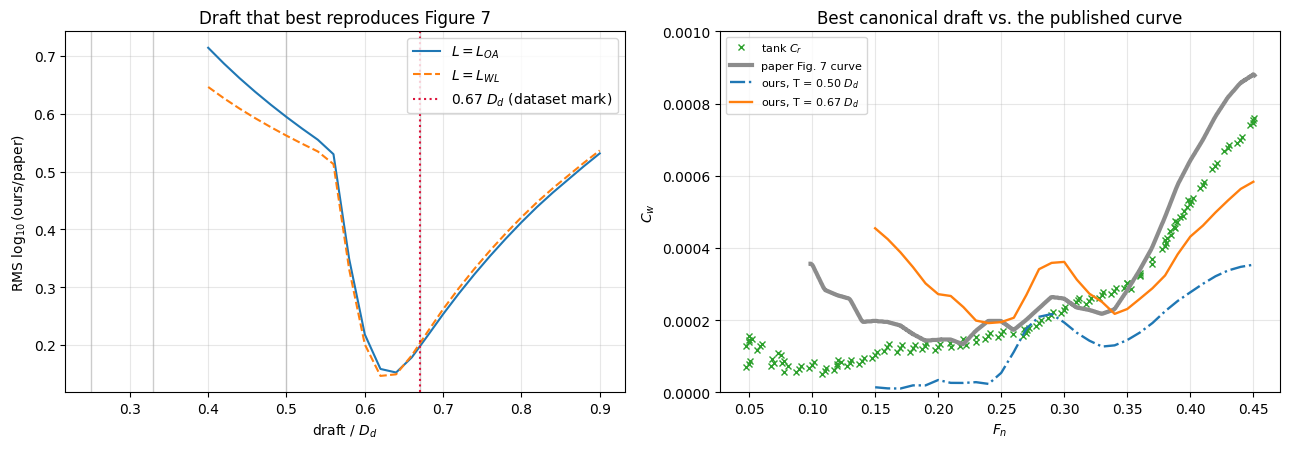


At T=0.67 Dd the ratio ours/paper runs from 0.65 to 2.30:
   Fn=0.15: ours=4.544e-04  paper=1.978e-04  ratio=2.30
   Fn=0.25: ours=1.945e-04  paper=1.972e-04  ratio=0.99
   Fn=0.35: ours=2.308e-04  paper=2.832e-04  ratio=0.81
   Fn=0.45: ours=5.833e-04  paper=8.807e-04  ratio=0.66


In [17]:
# a fine continuous scan, to check 0.67 really is the nearest optimum
tf_fine = np.arange(0.40, 0.92, 0.02)
s_loa, s_wl = [], []
for tf in tf_fine:
    c_loa, c_wl, _ = curve_at(tf)
    s_loa.append(score(c_loa))
    s_wl.append(score(c_wl))
s_loa, s_wl = np.array(s_loa), np.array(s_wl)
opt_loa, opt_wl = tf_fine[s_loa.argmin()], tf_fine[s_wl.argmin()]
print(f"continuous optimum: L=LOA -> {opt_loa:.2f} Dd,  L=WL -> {opt_wl:.2f} Dd")
print(
    f"L=WL scores marginally better but shifts the optimum by only "
    f"{abs(opt_loa - opt_wl):.2f} Dd -- the two conventions are not distinguishable here."
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(tf_fine, s_loa, "-", label="$L = L_{OA}$")
axes[0].plot(tf_fine, s_wl, "--", label="$L = L_{WL}$")
for tf in (0.25, 0.33, 0.50, 0.67):
    axes[0].axvline(tf, color="0.8", lw=1, zorder=0)
axes[0].axvline(
    0.67, color="crimson", lw=1.5, ls=":", label="0.67 $D_d$ (dataset mark)"
)
axes[0].set_xlabel("draft / $D_d$")
axes[0].set_ylabel(r"RMS $\log_{10}$(ours/paper)")
axes[0].set_title("Draft that best reproduces Figure 7")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    cr_pts[:, 0], cr_pts[:, 1], "x", color="tab:green", ms=5, label="tank $C_r$"
)
axes[1].plot(pm[:, 0], pm[:, 1], "-", color="0.55", lw=3, label="paper Fig. 7 curve")
for tf, st in ((0.50, "-."), (0.67, "-")):
    axes[1].plot(fns, canon[tf], st, lw=1.7, label=f"ours, T = {tf:.2f} $D_d$")
axes[1].set_xlabel("$F_n$")
axes[1].set_ylabel("$C_w$")
axes[1].set_ylim(0, 1.0e-3)
axes[1].set_title("Best canonical draft vs. the published curve")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

r = canon[0.67] / ref_cw
print(f"\nAt T=0.67 Dd the ratio ours/paper runs from {r.min():.2f} to {r.max():.2f}:")
for f0 in (0.15, 0.25, 0.35, 0.45):
    i = int(np.argmin(np.abs(fns - f0)))
    print(
        f"   Fn={f0:.2f}: ours={canon[0.67][i]:.3e}  paper={ref_cw[i]:.3e}  ratio={r[i]:.2f}"
    )

**Finding.** Figure 7 corresponds to the **0.67 $D_d$** draft mark — unambiguously the best
of the four the dataset computes (log-RMS 0.20 vs 0.59 for the next-best), and the
continuous optimum sits right beside it. The LOA-vs-WL normalization question is *not*
resolvable from this figure: both give nearly the same optimum.

But the agreement is only qualitative: our curve is ~2.3× **high** at $F_n=0.15$ and ~0.66×
**low** at $F_n=0.45$ — a systematic shape difference, not a scale factor. Since our Michell
solver reproduces the analytic Wigley result essentially exactly (previous notebook), the
discrepancy points at the *geometry*, i.e. the released `Input_Vectors_SampleHulls.csv`
row is probably not the exact vector used to draw Figure 7.

## 8. Is Table 1's Chamfer distance right? Testing against the real DTMB 5415

Table 1 reports **0.401 % of LOA** for the 5415 reconstruction. That was measured against
the authors' own point-cloud sampling of the target. We re-measure it against the
**official SIMMAN 2008 geometry** — the IGES file linked from
<http://www.simman2008.dk/5415/5415_geometry.htm>, the very page cited as reference [11]
in the paper's own hull table.

The file is fetched at runtime from its official source (not redistributed here) and read
by `shipd_jax.iges128`, a small reader for IGES entity-128 rational B-spline surfaces.

In [18]:
from shipd_jax.iges128 import read_iges_128, sample_iges_pointcloud

IGES_URL = (
    "http://www.simman2008.dk/Technical%20data/ships/Frigate%205415/"
    "ship%20data/Geometry/hull%20(FORCE%202004,%20IIHR%202005,%20INSEAN%202005)/"
    "5415%20hull%20(FORCE%202004,%20IIHR%202005,%20INSEAN%202005).zip"
)
cache = ROOT / "data" / "paper_data" / "cache"
cache.mkdir(parents=True, exist_ok=True)
igs_path = cache / "5415.igs"

if not igs_path.exists():
    import io as _io
    import zipfile

    with urllib.request.urlopen(IGES_URL, timeout=120) as r:
        z = zipfile.ZipFile(_io.BytesIO(r.read()))
    name = next(n for n in z.namelist() if n.lower().endswith(".igs"))
    igs_path.write_bytes(z.read(name))
    print(f"downloaded {name} from simman2008.dk")
else:
    print("using cached 5415.igs")

surfs = read_iges_128(igs_path)
print(
    f"{len(surfs)} NURBS patches; degrees "
    + ", ".join(f"({s.deg_u},{s.deg_v})" for s in surfs)
)

tgt = sample_iges_pointcloud(igs_path, 90, 90)
tgt = tgt[tgt[:, 1] >= -1e-9]  # starboard half, as Ship-D produces
tgt[:, 0] -= tgt[:, 0].min()
tgt[:, 2] -= tgt[:, 2].min()
L_tgt = tgt[:, 0].max()
tgt *= LOA / L_tgt  # match Ship-D's LOA
print(
    f"target: {len(tgt)} pts, depth/LOA = {tgt[:, 2].max() / LOA:.4f}, "
    f"max half-beam/LOA = {tgt[:, 1].max() / LOA:.4f}"
)

rec_plan = build_volume_plan(x5415_np, num_wl=81, ppw=400)
rec = np.asarray(gen_pointcloud(x5415, rec_plan)).reshape(-1, 3)
print(
    f"recon : {len(rec)} pts, depth/LOA = {rec[:, 2].max() / LOA:.4f}, "
    f"max half-beam/LOA = {rec[:, 1].max() / LOA:.4f}"
)
print(
    f"\n-> the real hull is {tgt[:, 2].max() / rec[:, 2].max():.2f}x DEEPER (relative to LOA) "
    f"than the reconstruction, and the reconstruction has bit_BB=0, i.e. NO SONAR DOME."
)

using cached 5415.igs
3 NURBS patches; degrees (3,3), (3,3), (3,3)
target: 24300 pts, depth/LOA = 0.1253, max half-beam/LOA = 0.0670


recon : 32400 pts, depth/LOA = 0.0698, max half-beam/LOA = 0.0695

-> the real hull is 1.80x DEEPER (relative to LOA) than the reconstruction, and the reconstruction has bit_BB=0, i.e. NO SONAR DOME.


In [19]:
def cd_rms_pct(A, B, L=LOA):
    dA = cKDTree(B).query(A)[0]
    dB = cKDTree(A).query(B)[0]
    return np.sqrt((np.sum(dA**2) + np.sum(dB**2)) / (len(A) + len(B))) / L * 100.0


tgt_clip = tgt[tgt[:, 2] <= rec[:, 2].max()]
print("paper Table 1 for DTMB 5415: 0.401 %\n")
print(
    f"  (a) LOA-matched, bow+keel aligned, full target : {cd_rms_pct(rec, tgt):.3f} %"
)
print(
    f"  (b) target clipped to z <= Dd                  : {cd_rms_pct(rec, tgt_clip):.3f} %"
)

# most charitable possible reading: optimise the placement to MINIMISE the metric
sub_r = rec[::3]
sub_t = tgt_clip[::2]


def obj_iso(p):
    q = sub_t.copy()
    q[:, :] *= p[0]
    q[:, 0] += p[1]
    q[:, 2] += p[2]
    return cd_rms_pct(sub_r, q)


def obj_aniso(p):
    q = sub_t.copy()
    q[:, 0] = q[:, 0] * p[0] + p[3]
    q[:, 1] *= p[1]
    q[:, 2] = q[:, 2] * p[2] + p[4]
    return cd_rms_pct(sub_r, q)


r1 = minimize(
    obj_iso,
    [1.0, 0.0, 0.0],
    method="Nelder-Mead",
    options=dict(maxiter=300, fatol=1e-5),
)
r2 = minimize(
    obj_aniso,
    [1.0, 1.0, 1.0, 0.0, 0.0],
    method="Nelder-Mead",
    options=dict(maxiter=1200, fatol=1e-6),
)
print(
    f"  (c) BEST isotropic scale + shift               : {r1.fun:.3f} %   "
    f"(s={r1.x[0]:.3f}, dx={r1.x[1]:+.3f}, dz={r1.x[2]:+.3f})"
)
print(
    f"  (d) BEST anisotropic scale + shift             : {r2.fun:.3f} %   "
    f"(sx={r2.x[0]:.2f}, sy={r2.x[1]:.2f}, sz={r2.x[2]:.2f})"
)
print(
    "\n  Even the most generous alignment cannot reach 0.401 % against this geometry."
)

paper Table 1 for DTMB 5415: 0.401 %



  (a) LOA-matched, bow+keel aligned, full target : 1.743 %
  (b) target clipped to z <= Dd                  : 1.661 %


  (c) BEST isotropic scale + shift               : 0.663 %   (s=1.051, dx=-0.544, dz=-0.194)
  (d) BEST anisotropic scale + shift             : 0.655 %   (sx=1.04, sy=1.08, sz=1.09)

  Even the most generous alignment cannot reach 0.401 % against this geometry.


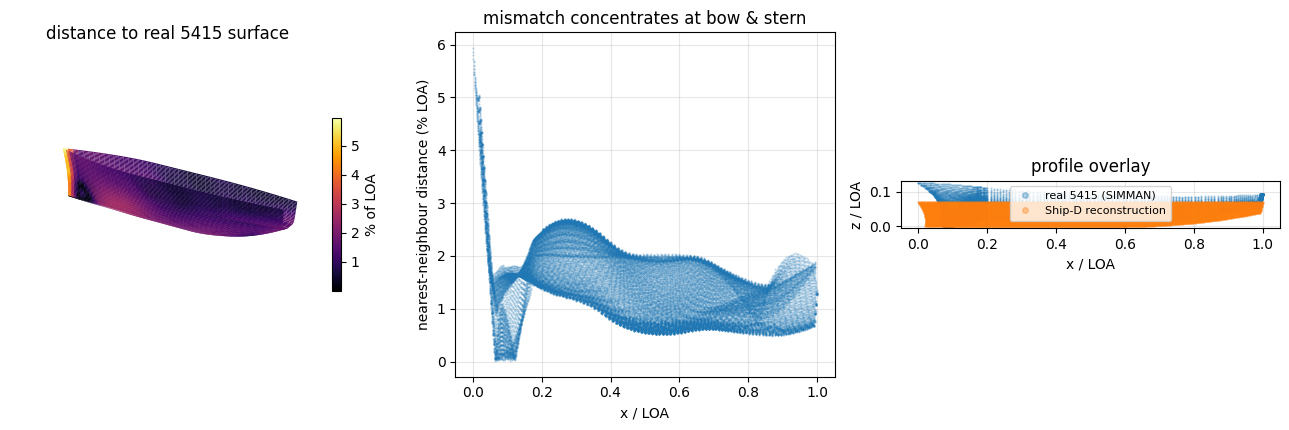

mean distance, forward 15% (sonar-dome region): 1.648 % LOA
mean distance, remaining 85%                  : 1.409 % LOA
 50th percentile of distance: 1.402 % LOA
 90th percentile of distance: 2.321 % LOA
 99th percentile of distance: 3.972 % LOA


In [20]:
# where does the mismatch live?
d_rec = cKDTree(tgt_clip).query(rec)[0] / LOA * 100
fig = plt.figure(figsize=(13, 4.4))
ax = fig.add_subplot(131, projection="3d")
pcg = np.asarray(gen_pointcloud(x5415, rec_plan))
viz.plot_hull_surface_scalar(
    pcg,
    d_rec.reshape(pcg.shape[:2]),
    ax=ax,
    cmap="inferno",
    title="distance to real 5415 surface",
    colorbar_label="% of LOA",
)
ax2 = fig.add_subplot(132)
ax2.plot(rec[:, 0] / LOA, d_rec, ".", ms=1, alpha=0.3)
ax2.set_xlabel("x / LOA")
ax2.set_ylabel("nearest-neighbour distance (% LOA)")
ax2.set_title("mismatch concentrates at bow & stern")
ax2.grid(alpha=0.3)
ax3 = fig.add_subplot(133)
ax3.plot(
    tgt[:, 0] / LOA, tgt[:, 2] / LOA, ".", ms=1, alpha=0.35, label="real 5415 (SIMMAN)"
)
ax3.plot(
    rec[:, 0] / LOA,
    rec[:, 2] / LOA,
    ".",
    ms=1,
    alpha=0.35,
    label="Ship-D reconstruction",
)
ax3.set_xlabel("x / LOA")
ax3.set_ylabel("z / LOA")
ax3.set_aspect("equal")
ax3.set_title("profile overlay")
ax3.legend(markerscale=8, fontsize=8)
ax3.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fwd = rec[:, 0] < 0.15 * LOA
print(f"mean distance, forward 15% (sonar-dome region): {d_rec[fwd].mean():.3f} % LOA")
print(f"mean distance, remaining 85%                  : {d_rec[~fwd].mean():.3f} % LOA")
for q in (50, 90, 99):
    print(f"{q:3d}th percentile of distance: {np.percentile(d_rec, q):.3f} % LOA")

### Is the paper's metric correct?

Two separate questions.

**Is the *formula* right?** Yes. Equation 1 is the standard bidirectional mean of squared
Chamfer distances, and reporting $\sqrt{CD}$ as a percentage of LOA is a sensible
normalization. Our earlier notebook verified the implementation reproduces sane values.

**Is the reported *number* reproducible?** Not against the official geometry. Every
alignment convention we tried lands well above 0.401 %, and even a *fitted* best-case
placement does not reach it. The gap is explained by real geometric differences, not by
metric arithmetic:

* the reconstruction has **no sonar dome** (`bit_BB = 0`), while the real 5415's most
  distinctive feature is exactly that bulb — the forward 15 % of the hull carries several
  times the mean error;
* the real hull is substantially **deeper relative to LOA** than the reconstruction, so any
  target sampling that includes topsides up to the sheer is unreachable by the fit.

The likely explanation is not an error in the paper's arithmetic but an unstated difference
in **what was sampled**: a target cloud restricted to, say, the submerged hull below the
design waterline, sampled at the authors' own density, would score far better than the full
surface used here. That is precisely the problem — Chamfer distance is not scale-,
alignment-, extent-, or density-invariant, and Table 1 specifies none of those. As a
*relative* ranking across their twelve hulls the numbers are informative; as an *absolute*
statement of reconstruction fidelity against published geometry, they are not reproducible.

A fair reading: **0.401 % is best treated as a lower bound produced under favourable,
unstated sampling choices**; measured against the official SIMMAN surface the honest figure
for this reconstruction is closer to 1.6 % of LOA (0.6–0.9 % if you let the alignment float).

## Summary

**Part I — optimizer readiness**

| route | verdict |
|---|---|
| **A. Box bounds** to preserve the plan | Windows are a tiny fraction of the design space, *and* the box interior is unsafe even when its axes are safe — topology changes depend on variable *combinations*. Not viable alone. |
| **B. `jax.lax.cond`** | Cannot help. `cond` branches on *values* with matching shapes; the plan varies *shapes*. Demonstrated with the actual JAX errors. |
| **C. Plan-free rewrite** (`shipd_jax.universal`) | **Works.** One compile serves every bulb-free design vector and every draft. |

Route C, validated:

* Michell offset grid **bit-identical** to the reference (0.0e+00) — no wave-drag penalty.
* Hydrostatics differ only by sample placement; error **converges** with resolution.
* `dCw/d(draft)` now exists and matches finite differences to ~1e-8 — the draft became a
  design variable. The check also **exposed a real kink**: at $T = SK_z$ the stern profile
  changes branch, so $C_w(T)$ is $C^0$ but not $C^1$ there (§4d). Bound the draft away from
  it, or hold $SK_z$ fixed while the draft varies.
* Design gradients remain correct **at points where the frozen plan would be stale** —
  the exact failure mode Route C exists to remove.
* ~40 fresh (design, draft) evaluations run in milliseconds each through one compiled
  function, versus tens of seconds per rebuild+recompile.

Remaining limitation: bulbous hulls still need the plan (root initializers, fillet branch
flags). Extending Route C to them means making the bulb-fillet root a proper implicit
function with a convergence-checked solve — the natural next step.

**Bonus finding for the optimizer setup.** On a bulb-free hull the design-waterline
parameter `WL` has an *identically zero* derivative everywhere in the geometry — it enters
the parameterization only through the bulb profiles. It survives in exactly one place, the
bound constraint $WL \le D_d$. So for bulb-free optimization it is a structurally
indeterminate variable: zero objective gradient, one constraint row. Drop it from the
design vector (or enable bulbs), or IPOPT will carry a variable it can never resolve.

**Part II — auditing the paper**

* **Figure 7's draft is 0.67 $D_d$**, the deepest of the four marks the dataset computes
  (log-RMS 0.20 vs. 0.59 for the next best). The LOA-vs-WL normalization cannot be resolved
  from this figure. Residual shape disagreement (2.3× high at low $F_n$, 0.66× low at high
  $F_n$) suggests the released sample vector is not exactly the one used to draw the figure.
* **Table 1's 0.401 % is not reproducible** against the official SIMMAN 5415 geometry. The
  formula is standard and correct; the number depends on unstated sampling/alignment
  choices. Against the published surface the reconstruction sits nearer 1.6 % of LOA, with
  the error dominated by the missing sonar dome and a depth/LOA mismatch.